import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

In [2]:
df = pd.read_csv("dataset/train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 891
Columns: 12


In [6]:
print(df.columns.tolist())

['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [7]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate records removed.")

Duplicates: 0
Duplicate records removed.


In [9]:
df["Age"] = df["Age"].fillna(df["Age"].median())
print("Missing Age values filled.")

Missing Age values filled.


In [10]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
print("Missing Embarked values filled.")

Missing Embarked values filled.


In [11]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [12]:
class TitanicAnalyzer:
    def __init__(self, data):
        self.data = data.copy()

    def display_data(self):
        return self.data.head()

    def dataset_info(self):
        return self.data.info()

    def check_missing_values(self):
        return self.data.isnull().sum()

    def calculate_survival_rate(self):
        rate = self.data["Survived"].mean() * 100
        return round(rate, 2)

    def survival_by_gender(self):
        return self.data.groupby("Sex")["Survived"].mean() * 100

    def survival_by_class(self):
        return self.data.groupby("Pclass")["Survived"].mean() * 100

In [13]:
analyzer = TitanicAnalyzer(df)
print("Titanic Analyzer created successfully!")

Titanic Analyzer created successfully!


In [14]:
analyzer.display_data()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
rate = analyzer.calculate_survival_rate()
print("Overall Survival Rate:", rate, "%")

Overall Survival Rate: 38.38 %


In [16]:
print("Total Passengers:", len(df))

Total Passengers: 891


In [17]:
survived = df["Survived"].sum()
print("Survived Passengers:", survived)

Survived Passengers: 342


In [18]:
not_survived = (df["Survived"] == 0).sum()
print("Not Survived:", not_survived)

Not Survived: 549


In [19]:
gender_survival = analyzer.survival_by_gender()
print(gender_survival)

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [20]:
class_survival = analyzer.survival_by_class()
print(class_survival)

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


In [21]:
print("Average Age:", round(df["Age"].mean(), 2))

Average Age: 29.36


In [22]:
print("Average Fare:", round(df["Fare"].mean(), 2))

Average Fare: 32.2


In [23]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"])

age_survival = df.groupby("AgeGroup",observed=False)["Survived"].mean() * 100
print(age_survival)

AgeGroup
Child          57.971014
Teenager       42.857143
Young Adult    35.327103
Adult          40.000000
Senior         22.727273
Name: Survived, dtype: float64


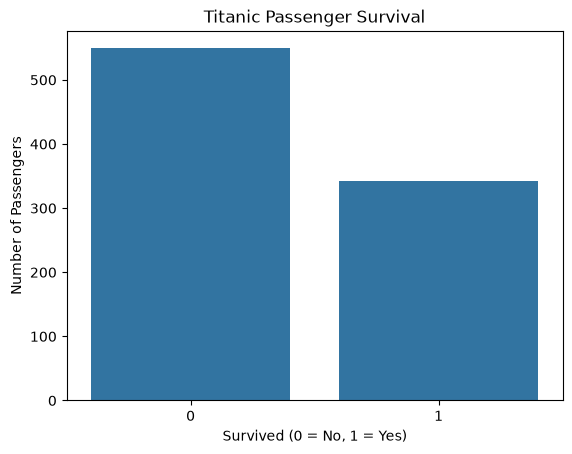

In [24]:
sns.countplot(data=df,x="Survived")
plt.title("Titanic Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.savefig("output/survival_count.png")
plt.show()

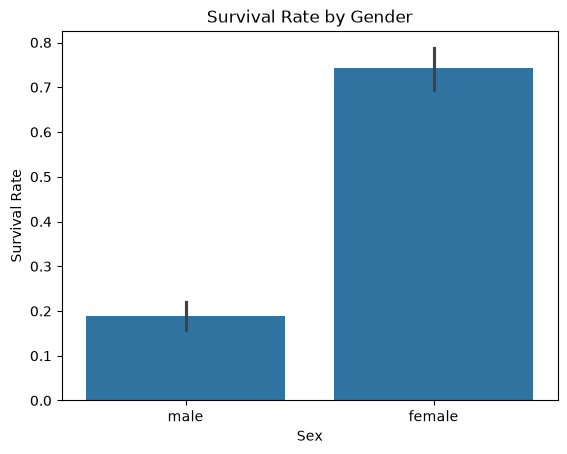

In [25]:
sns.barplot(data=df,x="Sex",y="Survived")
plt.title("Survival Rate by Gender")
plt.ylabel("Survival Rate")
plt.savefig("output/survival_by_gender.png")
plt.show()

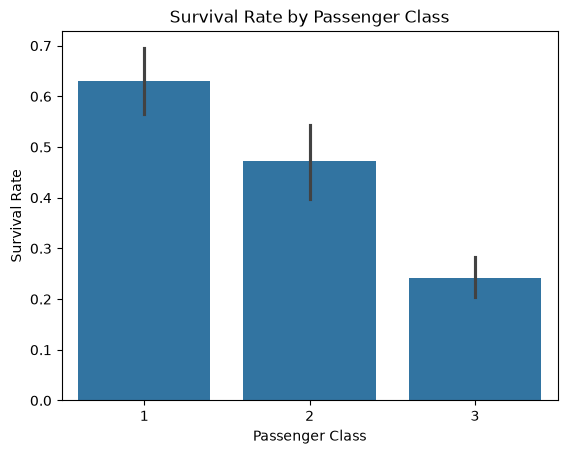

In [26]:
sns.barplot(data=df,x="Pclass",y="Survived")
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.savefig("output/survival_by_class.png")
plt.show()

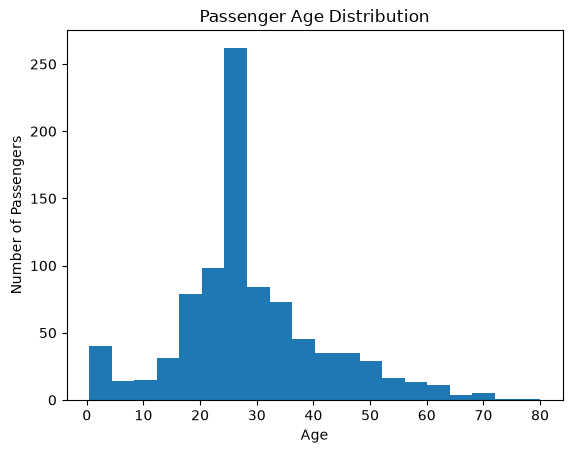

In [27]:
plt.hist(df["Age"],bins=20)
plt.title("Passenger Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.savefig("output/age_distribution.png")
plt.show()

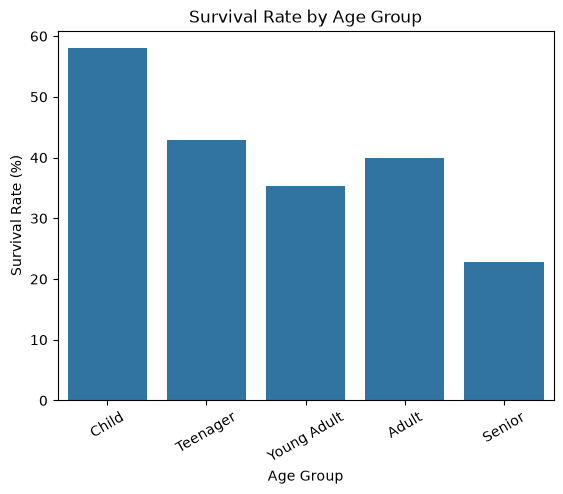

In [28]:
sns.barplot(x=age_survival.index,y=age_survival.values)
plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=30)
plt.savefig("output/survival_by_age.png")
plt.show()

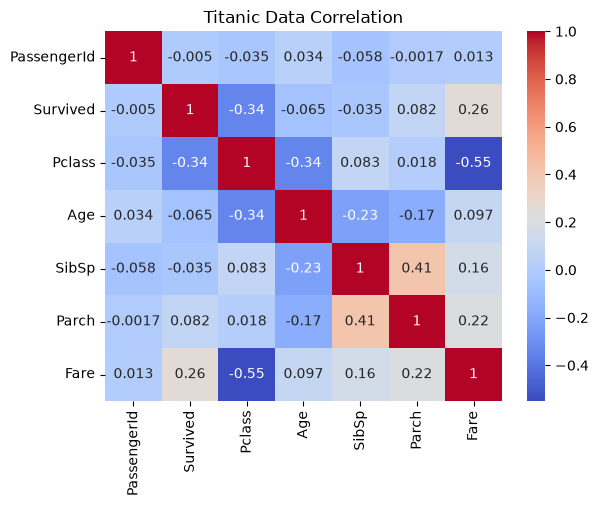

In [29]:
numeric_data = df.select_dtypes(include="number")
correlation = numeric_data.corr()
sns.heatmap(correlation,annot=True,cmap="coolwarm")
plt.title("Titanic Data Correlation")
plt.savefig("output/correlation_heatmap.png")
plt.show()

In [30]:
print("TITANIC SURVIVAL ANALYSIS")
print("-------------------------")
print("Total Passengers:", len(df))
print("Survived:",df["Survived"].sum())
print("Overall Survival Rate:",analyzer.calculate_survival_rate(),"%")
print("\nSurvival by Gender:")
print(analyzer.survival_by_gender())
print("\nSurvival by Passenger Class:")
print(analyzer.survival_by_class())

TITANIC SURVIVAL ANALYSIS
-------------------------
Total Passengers: 891
Survived: 342
Overall Survival Rate: 38.38 %

Survival by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
